# AI Lab: Linear Regression Optimization for Delivery Time

**Duration:** 1.5 hours  
**Input:** `Distance_km`  
**Target:** `Delivery_Time_min`

## Learning Outcomes

By the end of this lab, you should be able to:

- preprocess data for linear regression,
- train a one-input linear regression model,
- apply Mini-Batch Gradient Descent and Adam,
- change key optimization parameters,
- compare loss curves and model performance,
- explain what you observed.

## 1. Linear Regression Review

We use:

$$\hat{y}=wx+b$$


where:

- \(x\) = delivery distance,
- \(y\) = actual delivery time,
- $$\hat{y}\ = predicted delivery time.$$

Loss:

$$ MSE=\frac{1}{N}\sum (y- \hat{y})^2 $$

Reference reading:

https://arxiv.org/pdf/1609.04747

Focus on:

- Mini-Batch Gradient Descent
- RMSProp
- Adam
- Learning rate

## 2. Download the Dataset

Dataset:

https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction

Download `Food_Delivery_Times.csv` and place it in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

In [5]:
import kagglehub
import os 
# Download latest version
path = kagglehub.dataset_download("denkuznetz/food-delivery-time-prediction")

print("Path to dataset files:", path)
print(os.listdir(path))

Path to dataset files: C:\Users\U-ser\.cache\kagglehub\datasets\denkuznetz\food-delivery-time-prediction\versions\1
['Food_Delivery_Times.csv']


## 3. Load and Inspect the Data

In [7]:
df = pd.read_csv(os.path.join(path, "Food_Delivery_Times.csv"))

print(df.shape)
print(df.columns.tolist())
df.head()

(1000, 9)
['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Student Checkpoint

Answer briefly:

1. What is the input feature?
- The input feature are distance_km.
2. What is the target?
- The target is Delivery_time_min.
3. Name two other features that may also affect delivery time.
- Other relevant features that may also affect delivery time are Weather and Traffic_Level.

## 4. Preprocessing

In [8]:
data = df[["Distance_km", "Delivery_Time_min"]].copy()

print("Missing values:")
print(data.isna().sum())

data = data.dropna()

x = data["Distance_km"].to_numpy(dtype=float)
y = data["Delivery_Time_min"].to_numpy(dtype=float)

print("Samples after cleaning:", len(data))

Missing values:
Distance_km          0
Delivery_Time_min    0
dtype: int64
Samples after cleaning: 1000


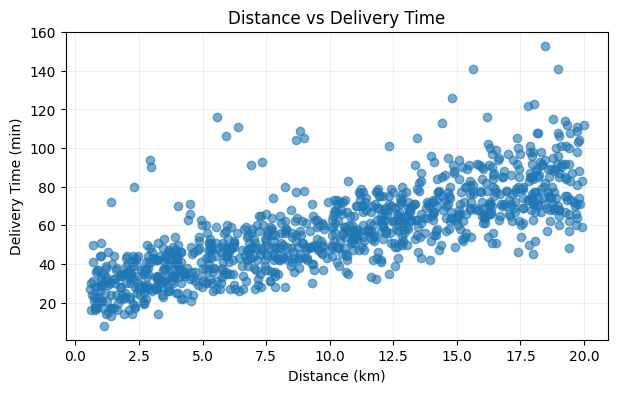

In [9]:
plt.figure(figsize=(7, 4))
plt.scatter(x, y, alpha=0.6)
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (min)")
plt.title("Distance vs Delivery Time")
plt.grid(alpha=0.2)
plt.show()

### Student Checkpoint

Write **2–3 sentences**:

- Is there a positive relationship?
* Answer: Delivery time generally increases as distance increases. This suggested a positive relationship between the delivery time and distance.

- Why is the relationship not perfectly linear?
* Answer: It is not perfectly linear because other features such as traffic, weather, and preparation time also affect delivery time. With high traffic, bad weather or long preparation can affected the delivery time to be longer even though the distance is not far.

## 5. Train/Test Split and Normalization

In [10]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(x))

train_size = int(0.8 * len(x))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

x_train, y_train = x[train_idx], y[train_idx]
x_test, y_test = x[test_idx], y[test_idx]

x_min = x_train.min()
x_max = x_train.max()

x_train_n = (x_train - x_min) / (x_max - x_min)
x_test_n = (x_test - x_min) / (x_max - x_min)

print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

Training samples: 800
Test samples: 200


### Student Checkpoint

Why do we calculate normalization values from the **training set only**?
- We calculate normalization values from the training set only is to prevent information from the test set leaking into training. By doing this it reduced bias, keeps scaling consistent and evaluation fair 

## 6. Linear Regression Functions

In [11]:
def predict(x, w, b):
    return w * x + b


def compute_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def compute_gradients(x, y, y_pred):
    dw = -2 * np.mean((y - y_pred) * x)
    db = -2 * np.mean(y - y_pred)
    return dw, db

## 7. Mini-Batch Gradient Descent

In [12]:
def train_minibatch(
    x, y,
    lr=0.01,
    epochs=100,
    batch_size=32,
    seed=42
):
    w, b = 0.0, 0.0
    loss_history = []

    rng = np.random.default_rng(seed)
    n = len(x)

    for epoch in range(epochs):

        idx = rng.permutation(n)
        x_s = x[idx]
        y_s = y[idx]

        for i in range(0, n, batch_size):

            xb = x_s[i:i+batch_size]
            yb = y_s[i:i+batch_size]

            pred = predict(xb, w, b)
            dw, db = compute_gradients(xb, yb, pred)

            w -= lr * dw
            b -= lr * db

        loss_history.append(
            compute_loss(y, predict(x, w, b))
        )

    return w, b, loss_history

## Student Experiment 1 — Change Batch Size

Run Mini-Batch GD using:

- `batch_size = 1`
- `batch_size = 32`
- `batch_size = len(x_train_n)`

Keep:

- `lr = 0.01`
- `epochs = 100`

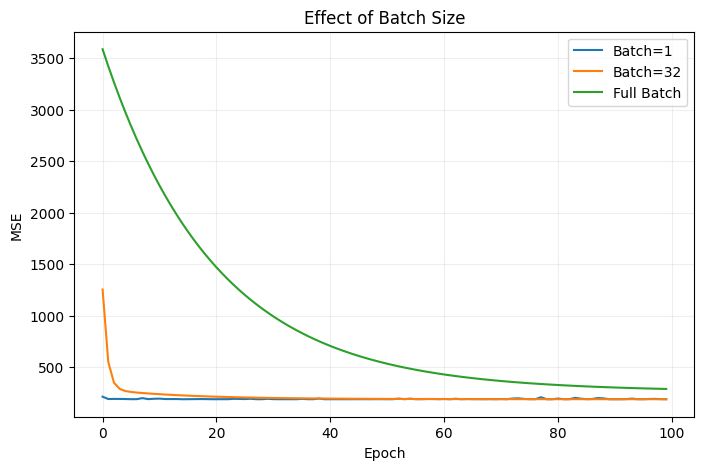

In [13]:
batch_sizes = [1, 32, len(x_train_n)]

plt.figure(figsize=(8, 5))

for bs in batch_sizes:

    w, b, losses = train_minibatch(
        x_train_n,
        y_train,
        lr=0.01,
        epochs=100,
        batch_size=bs,
        seed=SEED
    )

    label = "Full Batch" if bs == len(x_train_n) else f"Batch={bs}"
    plt.plot(losses, label=label)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Effect of Batch Size")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Write Your Insight

Write **3–4 sentences**:

- Which batch size converged faster?
- Which curve was smoother?
- What happens when batch size becomes very small?

* Answer: With the same learning rate and number of epochs, batch size 1 typically converges faster per epoch because it updates the paremeters after every sample. Full-batch gradient descent produces the smoothest curves but also improve more slowly because it updates only once ber epoch. When the batch size becomes very small it create noiser gradients which can cause the loss to fluctuate back and forth.

## 8. Adam Optimizer (Adaptive Moment Estimation)

Adam keeps **two** running averages of the gradient for each parameter:

- $m_t$: an exponential moving average of the gradient itself (like momentum) —
  controlled by $\beta_1$ (typically 0.9)
- $v_t$: an exponential moving average of the **squared** gradient (like
  RMSProp) — controlled by $\beta_2$ (typically 0.999)

At each step $t$:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t \qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$

Because $m_t$ and $v_t$ start at 0, they are biased toward 0 early in training,
so Adam applies a **bias correction**:

$$\hat{m}_t = \frac{m_t}{1-\beta_1^t} \qquad \hat{v}_t = \frac{v_t}{1-\beta_2^t}$$

and finally updates the parameter:

$$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t}+\epsilon}\,\hat{m}_t$$

See Section on Adam in the Ruder overview paper (arXiv:1609.04747) for the full
derivation and intuition. Now implement it below — `dw`/`db` play the role of
$g_t$ for `w` and `b` respectively.


Adam uses:

- first moment \(m\): moving average of gradients,
- second moment \(v\): moving average of squared gradients,
- bias correction,
- adaptive parameter updates.

In [14]:
def train_adam(
    x, y,
    lr=0.01,
    epochs=100,
    batch_size=32,
    beta1=0.9,
    beta2=0.999,
    eps=1e-8,
    seed=42
):
    w, b = 0.0, 0.0

    mw = vw = 0.0
    mb = vb = 0.0

    t = 0
    loss_history = []

    rng = np.random.default_rng(seed)
    n = len(x)

    for epoch in range(epochs):

        idx = rng.permutation(n)
        x_s = x[idx]
        y_s = y[idx]

        for i in range(0, n, batch_size):

            xb = x_s[i:i+batch_size]
            yb = y_s[i:i+batch_size]

            pred = predict(xb, w, b)
            dw, db = compute_gradients(xb, yb, pred)

            t += 1

            mw = beta1 * mw + (1-beta1) * dw
            mb = beta1 * mb + (1-beta1) * db

            vw = beta2 * vw + (1-beta2) * dw**2
            vb = beta2 * vb + (1-beta2) * db**2

            mw_hat = mw / (1-beta1**t)
            mb_hat = mb / (1-beta1**t)

            vw_hat = vw / (1-beta2**t)
            vb_hat = vb / (1-beta2**t)

            w -= lr * mw_hat / (np.sqrt(vw_hat) + eps)
            b -= lr * mb_hat / (np.sqrt(vb_hat) + eps)

        loss_history.append(
            compute_loss(y, predict(x, w, b))
        )

    return w, b, loss_history

## Student Experiment 2 — Change Adam Learning Rate

Test:

- `0.001`
- `0.01`
- `0.05`

Keep:

- `batch_size = 32`
- `epochs = 100`

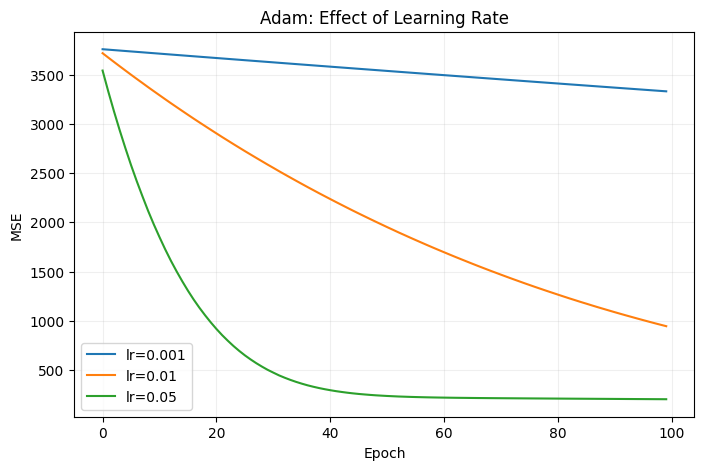

In [15]:
learning_rates = [0.001, 0.01, 0.05]

plt.figure(figsize=(8, 5))

for lr in learning_rates:

    w, b, losses = train_adam(
        x_train_n,
        y_train,
        lr=lr,
        epochs=100,
        batch_size=32,
        seed=SEED
    )

    plt.plot(losses, label=f"lr={lr}")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Adam: Effect of Learning Rate")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Write Your Insight

Write **3–4 sentences**:

- Which learning rate converged faster?
- Did any learning rate become unstable?
- Does Adam remove the need to choose a good learning rate?

- Answer: The learning rate of 0.05 converged the fastest, while 0.001 learns very slowly. A learning rate of 0.01 provides moderate progress. According to the graph shown all curves decreases without large spikes or fluctuation. Therefore, all the learning rate did not show clear instability in this experiment. Even if we use Adam it stills requires a good learning rate because a rate too small will slows the learning, while one that is too large can cause instability.

## 9. Compare Mini-Batch GD and Adam

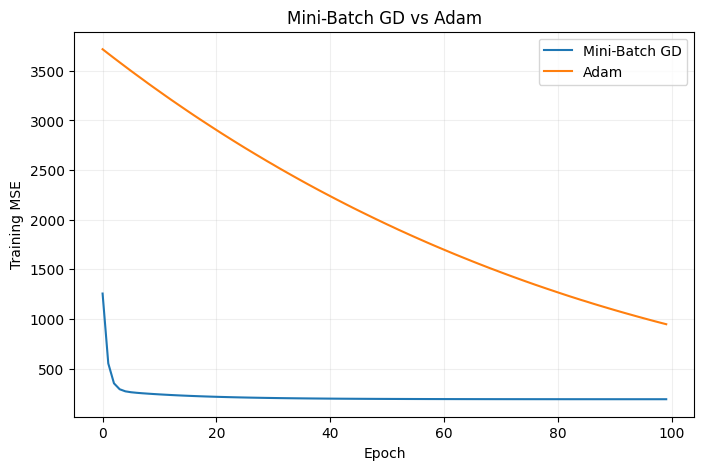

In [16]:
w_mini, b_mini, loss_mini = train_minibatch(
    x_train_n,
    y_train,
    lr=0.01,
    epochs=100,
    batch_size=32,
    seed=SEED
)

w_adam, b_adam, loss_adam = train_adam(
    x_train_n,
    y_train,
    lr=0.01,
    epochs=100,
    batch_size=32,
    seed=SEED
)

plt.figure(figsize=(8, 5))
plt.plot(loss_mini, label="Mini-Batch GD")
plt.plot(loss_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Mini-Batch GD vs Adam")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [17]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

mini_test_mse = mse(
    y_test,
    predict(x_test_n, w_mini, b_mini)
)

adam_test_mse = mse(
    y_test,
    predict(x_test_n, w_adam, b_adam)
)

print("Mini-Batch GD Test MSE:", mini_test_mse)
print("Adam Test MSE         :", adam_test_mse)

Mini-Batch GD Test MSE: 186.23627264707878
Adam Test MSE         : 855.7494363325646


## Final Insight

Write **5–6 sentences**:

1. Which optimizer reduced loss faster?
- Mini-Batch GD reduced loss faster than Adam at the same learning rate of 0.01.
2. Which produced lower test MSE?
- The Mini-Batch GD test produced lower test MSE.
3. How did batch size affect Mini-Batch GD?
- Smaller batches generally learned faster per epoch but produced noiser updates.
4. How did learning rate affect Adam?
- Inccreasing Adam's learning rate improved convergence speed in this experiment.
5. Why should we not say that Adam is always the best optimizer?
- Adam is not always best because performance actually depends on the dataset, learning rate, and training duration.
6. Why can distance alone not perfectly predict delivery time?
- Distance alone cannot perfectly predict delivery time because traffic, weather, and preparation time also influence it.

## Submission

Submit the completed notebook with:

- preprocessing,
- graphs,
- batch-size experiment,
- Adam learning-rate experiment,
- optimizer comparison,
- written insights.